# DSC 411/511
# Cluster Validation and Interpretation



---
# Section 0: Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from sklearn.datasets import load_iris, load_wine

sns.set_style('whitegrid')
SEED = 0
print('ready')

ready


In [2]:
DATA_URL = 'https://jse.amstat.org/v19n3/decock/AmesHousing.txt'
df = pd.read_csv(DATA_URL, sep='\t')       # tab separated
print('Rows:', df.shape[0], ' Columns:', df.shape[1])

Rows: 2930  Columns: 82


In [3]:
FEATURES = ['Gr Liv Area', 'Lot Area', 'Overall Qual', 'Year Built',
            'Total Bsmt SF', 'Garage Area', 'TotRms AbvGrd', 'Full Bath']

work = df[FEATURES + ['SalePrice', 'Neighborhood']].copy()
work[FEATURES] = work[FEATURES].fillna(work[FEATURES].median())

X  = work[FEATURES]
scaler = StandardScaler().fit(X)
Xs = scaler.transform(X)
Z2 = PCA(n_components=2).fit_transform(Xs)

print(f'{Xs.shape[0]:,} houses, {Xs.shape[1]} columns, standardized')

2,930 houses, 8 columns, standardized


In [4]:
# Rebuild the three clusterings from the last two classes
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Xs)
hc = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(Xs)
db = DBSCAN(eps=1.2, min_samples=16).fit(Xs)

work['kmeans'] = km.labels_
work['hier']   = hc.labels_
work['dbscan'] = db.labels_

for name, lab in [('k-means', km.labels_), ('Hierarchical', hc.labels_),
                  ('DBSCAN', db.labels_)]:
    n_c = len(set(lab) - {-1})
    n_n = int((lab == -1).sum())
    print(f'{name:<14} {n_c} clusters, {n_n:,} noise, sizes {np.bincount(lab[lab >= 0])}')

k-means        4 clusters, 0 noise, sizes [ 466 1375 1085    4]
Hierarchical   4 clusters, 0 noise, sizes [1553  468  905    4]
DBSCAN         2 clusters, 447 noise, sizes [1189 1294]


---
# Section 1: Silhouette

For every point, two questions:

- **a** = average distance to the other points in **my own** cluster
- **b** = average distance to the points in the **nearest other** cluster

```
s = (b - a) / max(a, b)
```

| s | Meaning |
|---|---|
| near +1 | deep inside my cluster, far from any other |
| near 0 | on the boundary, could go either way |
| negative | closer to another cluster than to my own |

In [5]:
# Work it out by hand for one house, so nothing is hidden
i = 0
lab = km.labels_
mine = lab[i]

same  = Xs[(lab == mine)]
a = np.linalg.norm(Xs[i] - same, axis=1).sum() / (len(same) - 1)

b_each = {}
for c in sorted(set(lab) - {mine}):
    other = Xs[lab == c]
    b_each[c] = np.linalg.norm(Xs[i] - other, axis=1).mean()
nearest = min(b_each, key=b_each.get)
b = b_each[nearest]

print(f'House {i}, assigned to cluster {mine}')
print()
print(f'  a = average distance to the {len(same)-1:,} other houses in cluster {mine}')
print(f'      a = {a:.4f}')
print()
print('  average distance to each OTHER cluster:')
for c, v in sorted(b_each.items(), key=lambda t: t[1]):
    mark = '   <- nearest' if c == nearest else ''
    print(f'      cluster {c}: {v:.4f}{mark}')
print(f'      b = {b:.4f}')
print()
print(f'  s = (b - a) / max(a, b)')
print(f'    = ({b:.4f} - {a:.4f}) / {max(a,b):.4f}')
print(f'    = {(b-a)/max(a,b):.4f}')
print()
print(f'  sklearn agrees: {silhouette_samples(Xs, lab)[i]:.4f}')

House 0, assigned to cluster 1

  a = average distance to the 1,374 other houses in cluster 1
      a = 3.8378

  average distance to each OTHER cluster:
      cluster 2: 3.9124   <- nearest
      cluster 0: 4.6881
      cluster 3: 16.9494
      b = 3.9124

  s = (b - a) / max(a, b)
    = (3.9124 - 3.8378) / 3.9124
    = 0.0191

  sklearn agrees: 0.0191


In [6]:
print('SILHOUETTE FOR THE THREE AMES CLUSTERINGS')
print()
for name, l in [('k-means', km.labels_), ('Hierarchical', hc.labels_)]:
    print(f'   {name:<16} {silhouette_score(Xs, l):.4f}')
nz = db.labels_ != -1
if len(set(db.labels_[nz])) >= 2:
    print(f'   {"DBSCAN":<16} {silhouette_score(Xs[nz], db.labels_[nz]):.4f}   '
          f'(noise excluded, {int((~nz).sum()):,} houses dropped)')
print()
print('   For reference:')
print('      above 0.50   clear, well separated')
print('      0.25 to 0.50 some structure, clusters overlap')
print('      below 0.25   little or no real structure')

SILHOUETTE FOR THE THREE AMES CLUSTERINGS

   k-means          0.2610
   Hierarchical     0.2251
   DBSCAN           0.3618   (noise excluded, 447 houses dropped)

   For reference:
      above 0.50   clear, well separated
      0.25 to 0.50 some structure, clusters overlap
      below 0.25   little or no real structure


In [7]:
# Silhouette across k. Does any k look good?
rows = []
for k in range(2, 11):
    m = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    rows.append({'k': k,
                 'silhouette': round(silhouette_score(Xs, m.labels_), 4),
                 'Davies-Bouldin': round(davies_bouldin_score(Xs, m.labels_), 4)})
sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))
print()
print(f"Best silhouette : k = {sweep.loc[sweep['silhouette'].idxmax(), 'k']}  "
      f"({sweep['silhouette'].max():.4f})")
print(f"Best DB (lowest): k = {sweep.loc[sweep['Davies-Bouldin'].idxmin(), 'k']}")
print()
print('Note the direction of each measure:')
print('   silhouette        HIGHER is better')
print('   Davies-Bouldin    LOWER  is better')
print('   Calinski-Harabasz HIGHER is better')

 k  silhouette  Davies-Bouldin
 2      0.3203          1.2445
 3      0.2587          1.5018
 4      0.2610          1.1820
 5      0.2684          1.2154
 6      0.2017          1.3584
 7      0.1960          1.4106
 8      0.1825          1.4443
 9      0.1799          1.4623
10      0.1906          1.4274

Best silhouette : k = 2  (0.3203)
Best DB (lowest): k = 4

Note the direction of each measure:
   silhouette        HIGHER is better
   Davies-Bouldin    LOWER  is better
   Calinski-Harabasz HIGHER is better


---
# Section 2: The Silhouette Plot

One number hides a lot. Draw every point's score and you can see which clusters
are solid and which are not.

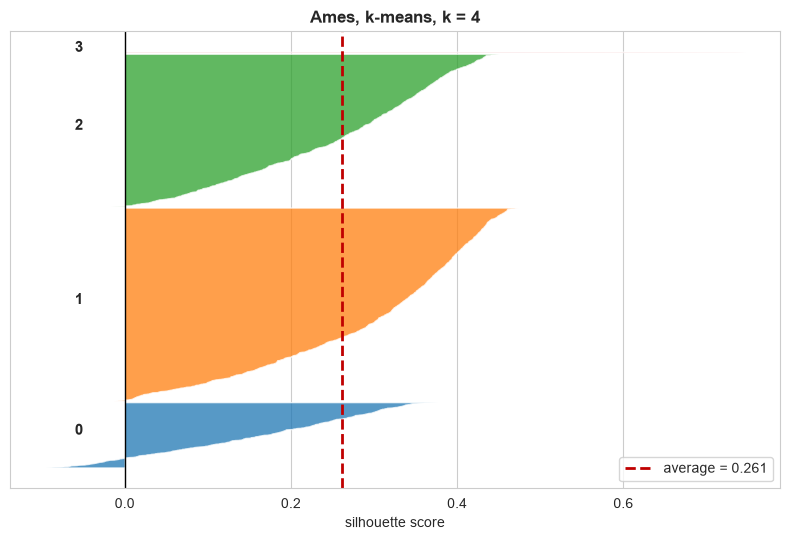

HOW TO READ IT
   Each cluster is a block. Wide block = many houses.
   Long bars to the right = confidently placed houses.
   Bars at or below zero  = houses that arguably belong elsewhere.

   Houses with a NEGATIVE score: 83 (2.8%)

   cluster 0:   466 houses, average   0.156,   72 negative
   cluster 1: 1,375 houses, average   0.297,    8 negative
   cluster 2: 1,085 houses, average   0.259,    3 negative
   cluster 3:     4 houses, average   0.623,    0 negative


In [8]:
def silhouette_plot(Xd, labels, title, ax=None):
    vals = silhouette_samples(Xd, labels)
    avg = vals.mean()
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5.5))
    y = 10
    for c in sorted(set(labels)):
        v = np.sort(vals[labels == c])
        ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, alpha=.75)
        ax.text(-0.06, y + len(v) / 2, str(c), fontsize=11, fontweight='bold')
        y += len(v) + 10
    ax.axvline(avg, color='#C00000', ls='--', lw=2,
               label=f'average = {avg:.3f}')
    ax.axvline(0, color='black', lw=1)
    ax.set_xlabel('silhouette score'); ax.set_yticks([])
    ax.set_title(title, fontsize=12.5, fontweight='bold')
    ax.legend(fontsize=10)
    return vals

vals = silhouette_plot(Xs, km.labels_, f'Ames, k-means, k = {K}')
plt.tight_layout(); plt.show()

print('HOW TO READ IT')
print('   Each cluster is a block. Wide block = many houses.')
print('   Long bars to the right = confidently placed houses.')
print('   Bars at or below zero  = houses that arguably belong elsewhere.')
print()
print(f'   Houses with a NEGATIVE score: {int((vals < 0).sum()):,} '
      f'({(vals < 0).mean()*100:.1f}%)')
print()
for c in sorted(set(km.labels_)):
    v = vals[km.labels_ == c]
    print(f'   cluster {c}: {len(v):>5,} houses, average {v.mean():>7.3f}, '
          f'{int((v < 0).sum()):>4} negative')

---
# Section 3: Davies-Bouldin

Same two ingredients as silhouette, combined differently.

- **Step 1.** Find each cluster's centroid.
- **Step 2.** Measure each cluster's spread: average distance from members to its centroid.
- **Step 3.** For every pair, measure the distance between their centroids.
- **Step 4.** Ratio for each pair: `(spread A + spread B) / distance AB`
- **Step 5.** For each cluster, keep its **worst** ratio.
- **Step 6.** Average those worst cases. **Lower is better.**

In [9]:
from itertools import combinations

lab = km.labels_
cen = np.array([Xs[lab == c].mean(0) for c in range(K)])
S   = np.array([np.linalg.norm(Xs[lab == c] - cen[c], axis=1).mean() for c in range(K)])

print('STEP 2: spread of each cluster')
for c in range(K):
    print(f'   S_{c} = {S[c]:.4f}   ({int((lab == c).sum()):,} houses)')
print()
print('STEP 3 and 4: distance between centroids, and the ratio')
R = {}
for a, b in combinations(range(K), 2):
    M = np.linalg.norm(cen[a] - cen[b])
    R[(a, b)] = (S[a] + S[b]) / M
    print(f'   M_{a}{b} = {M:.4f}    R_{a}{b} = ({S[a]:.3f} + {S[b]:.3f}) / {M:.3f} '
          f'= {R[(a,b)]:.4f}')
print()
print('STEP 5: each cluster keeps its worst')
worst = {}
for c in range(K):
    mine = {p: v for p, v in R.items() if c in p}
    worst[c] = max(mine.values())
    print(f'   cluster {c}: ratios ' +
          ', '.join(f'{v:.3f}' for v in mine.values()) + f'   -> worst {worst[c]:.4f}')
print()
print('STEP 6: average the worst cases')
dbi = np.mean(list(worst.values()))
print(f'   DB = ({" + ".join(f"{worst[c]:.3f}" for c in range(K))}) / {K} = {dbi:.4f}')
print()
print(f'   sklearn agrees: {davies_bouldin_score(Xs, lab):.4f}')
print()
print('   A value near 1 means the clusters are about as wide as the gaps between them.')

STEP 2: spread of each cluster
   S_0 = 2.1902   (466 houses)
   S_1 = 1.7806   (1,375 houses)
   S_2 = 1.7537   (1,085 houses)
   S_3 = 3.8210   (4 houses)

STEP 3 and 4: distance between centroids, and the ratio
   M_01 = 4.8051    R_01 = (2.190 + 1.781) / 4.805 = 0.8264
   M_02 = 2.5793    R_02 = (2.190 + 1.754) / 2.579 = 1.5291
   M_03 = 19.1424    R_03 = (2.190 + 3.821) / 19.142 = 0.3140
   M_12 = 2.6066    R_12 = (1.781 + 1.754) / 2.607 = 1.3559
   M_13 = 19.8893    R_13 = (1.781 + 3.821) / 19.889 = 0.2816
   M_23 = 19.6144    R_23 = (1.754 + 3.821) / 19.614 = 0.2842

STEP 5: each cluster keeps its worst
   cluster 0: ratios 0.826, 1.529, 0.314   -> worst 1.5291
   cluster 1: ratios 0.826, 1.356, 0.282   -> worst 1.3559
   cluster 2: ratios 1.529, 1.356, 0.284   -> worst 1.5291
   cluster 3: ratios 0.314, 0.282, 0.284   -> worst 0.3140

STEP 6: average the worst cases
   DB = (1.529 + 1.356 + 1.529 + 0.314) / 4 = 1.1820

   sklearn agrees: 1.1820

   A value near 1 means the clus

---
# Section 4: The Noise Baseline

The most important check in this whole lecture.

**Every algorithm returns clusters, including on data with no structure at all.**
So before believing your score, find out what a meaningless clustering would score.

In [10]:
rng = np.random.default_rng(SEED)
noise = rng.normal(0, 1, size=Xs.shape)          # same shape, zero structure

km_n = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(noise)

print(f'Clustering {noise.shape[0]:,} rows of PURE RANDOM NUMBERS into {K} groups')
print()
print(f"{'':>18}{'real Ames':>12}{'random noise':>15}")
print(f"{'silhouette':>18}{silhouette_score(Xs, km.labels_):>12.4f}"
      f"{silhouette_score(noise, km_n.labels_):>15.4f}")
print(f"{'Davies-Bouldin':>18}{davies_bouldin_score(Xs, km.labels_):>12.4f}"
      f"{davies_bouldin_score(noise, km_n.labels_):>15.4f}")
print(f"{'cluster sizes':>18}{str(np.bincount(km.labels_)):>12}"
      f"{str(np.bincount(km_n.labels_)):>15}")
print()
ratio = silhouette_score(Xs, km.labels_) / silhouette_score(noise, km_n.labels_)
print(f'Ames scores {ratio:.1f} times better than noise on silhouette.')
print()
print('The algorithm did not complain. It returned four tidy groups from nothing.')
print('The RATIO is your evidence, not the raw number.')

Clustering 2,930 rows of PURE RANDOM NUMBERS into 4 groups

                     real Ames   random noise
        silhouette      0.2610         0.0807
    Davies-Bouldin      1.1820         2.4304
     cluster sizes[ 466 1375 1085    4][730 722 744 734]

Ames scores 3.2 times better than noise on silhouette.

The algorithm did not complain. It returned four tidy groups from nothing.
The RATIO is your evidence, not the raw number.


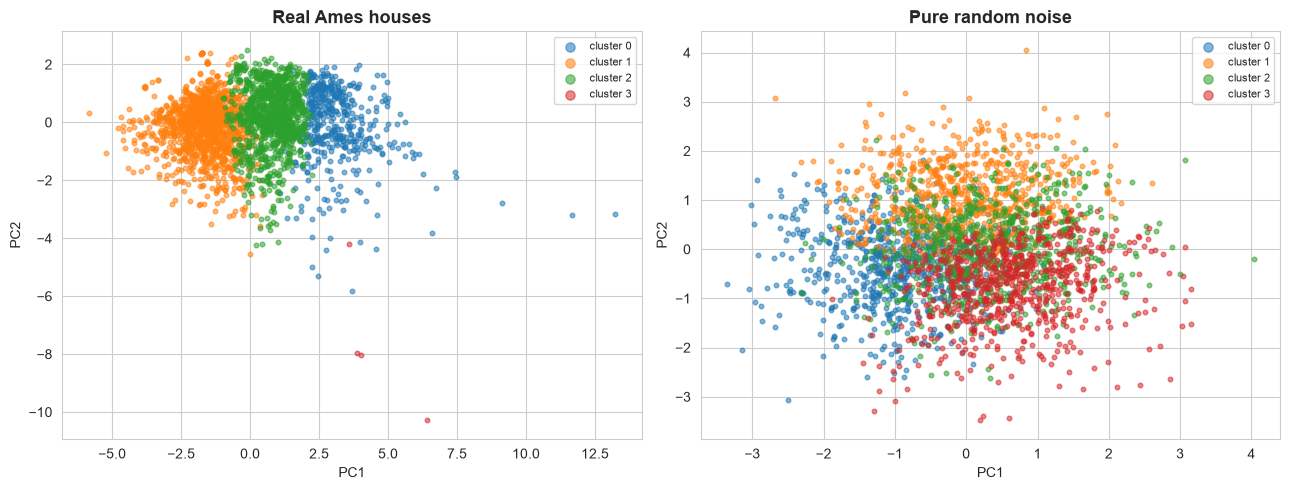

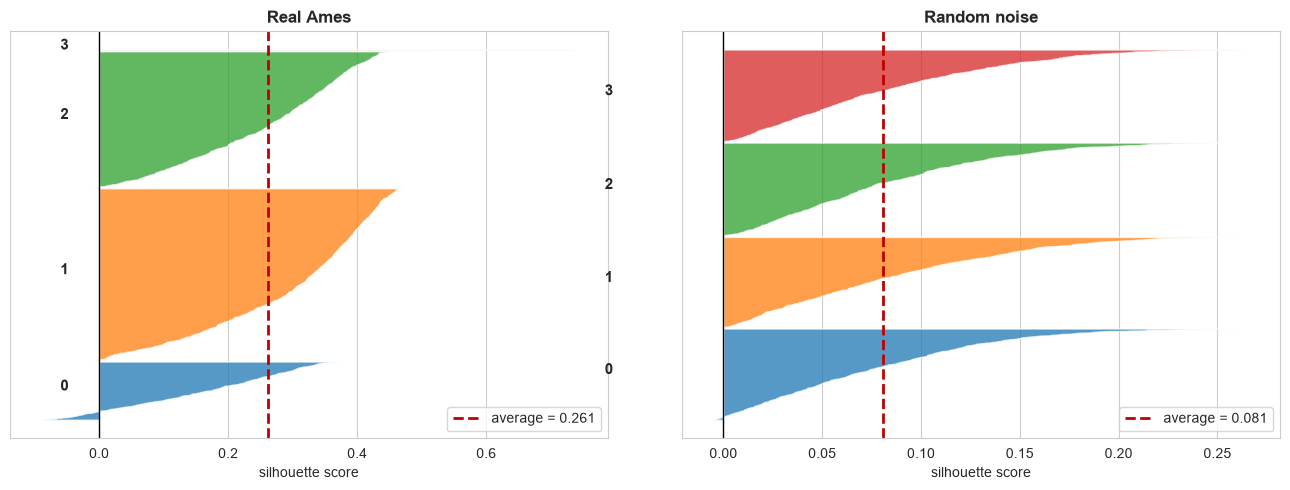

Both pictures look like clusters. Only one of them is.


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pn = PCA(n_components=2).fit_transform(noise)
for a_, dat, l, name in [(ax[0], Z2, km.labels_, 'Real Ames houses'),
                         (ax[1], pn, km_n.labels_, 'Pure random noise')]:
    for c in range(K):
        m = l == c
        a_.scatter(dat[m, 0], dat[m, 1], s=11, alpha=.55, label=f'cluster {c}')
    a_.set_title(name, fontsize=13, fontweight='bold')
    a_.set_xlabel('PC1'); a_.set_ylabel('PC2'); a_.legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
silhouette_plot(Xs, km.labels_, 'Real Ames', ax=ax[0])
silhouette_plot(noise, km_n.labels_, 'Random noise', ax=ax[1])
plt.tight_layout(); plt.show()

print('Both pictures look like clusters. Only one of them is.')

---
# Section 5: Stability Across Seeds

Silhouette says whether a clustering is tight. It does not say whether you would
get the same clustering again.

**Adjusted Rand Index** compares two clusterings by looking at every **pair** of
points: did both runs put them together, or both apart? Cluster numbers are
ignored, and chance agreement is subtracted.

In [12]:
base = KMeans(n_clusters=K, n_init=20, random_state=0).fit(Xs).labels_

print('Agreement with the run above, changing only the random seed:')
for s in [1, 7, 42, 99, 123]:
    l = KMeans(n_clusters=K, n_init=20, random_state=s).fit(Xs).labels_
    print(f'   seed {s:>3}:  ARI = {adjusted_rand_score(base, l):.4f}   '
          f'sizes {np.bincount(l)}')
print()
print('   1.0  identical grouping')
print('   0.0  no better than chance')

Agreement with the run above, changing only the random seed:
   seed   1:  ARI = 0.9932   sizes [ 465 1081 1380    4]
   seed   7:  ARI = 0.9992   sizes [1086  465 1375    4]
   seed  42:  ARI = 0.7589   sizes [ 919 1204  430  377]
   seed  99:  ARI = 0.9968   sizes [1377 1084  465    4]
   seed 123:  ARI = 0.9976   sizes [1083 1377  466    4]

   1.0  identical grouping
   0.0  no better than chance


In [13]:
# Stability under a change of sample, not just a change of seed
print('Cluster each half of the data separately. Do the price ladders match?')
print()
half = work.sample(frac=0.5, random_state=1).index
for name, sub in [('First half ', work.loc[half]), ('Second half', work.drop(half))]:
    Xh = scaler.transform(sub[FEATURES])
    m = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Xh)
    prof = (sub.assign(c=m.labels_).groupby('c')['SalePrice']
              .agg(['size', 'mean']).sort_values('mean'))
    print(f'{name}: ' + '   '.join(f'${v:,.0f} (n={int(n)})' for n, v in prof.values))
    tiny = prof[prof['size'] < 20]
    if len(tiny):
        print(f'             WARNING: {len(tiny)} cluster(s) with under 20 houses. '
              f'Outlier pockets, not market segments.')
print()
print('Similar ladders means the structure survives a change of sample.')

Cluster each half of the data separately. Do the price ladders match?

First half : $126,779 (n=620)   $157,368 (n=205)   $197,563 (n=429)   $321,034 (n=211)
Second half: $127,768 (n=646)   $191,467 (n=574)   $301,580 (n=242)   $318,000 (n=3)

Similar ladders means the structure survives a change of sample.


---
# Section 6: A Dataset Where Clustering Works

Everything above scored badly. Is that the method, or the data?

**Iris.** 150 flowers, 4 measurements, 3 species. We cluster without the species
labels, then use them only at the end to check.

In [14]:
iris = load_iris()
Xi = StandardScaler().fit_transform(iris.data)
yi = iris.target

km_i = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(Xi)

print('IRIS')
print(f'   {Xi.shape[0]} flowers, {Xi.shape[1]} measurements, 3 species')
print()
print(f'   silhouette     : {silhouette_score(Xi, km_i.labels_):.4f}')
print(f'   Davies-Bouldin : {davies_bouldin_score(Xi, km_i.labels_):.4f}')
print()
print('AMES, for comparison')
print(f'   silhouette     : {silhouette_score(Xs, km.labels_):.4f}')
print(f'   Davies-Bouldin : {davies_bouldin_score(Xs, km.labels_):.4f}')

IRIS
   150 flowers, 4 measurements, 3 species

   silhouette     : 0.4599
   Davies-Bouldin : 0.8336

AMES, for comparison
   silhouette     : 0.2610
   Davies-Bouldin : 1.1820


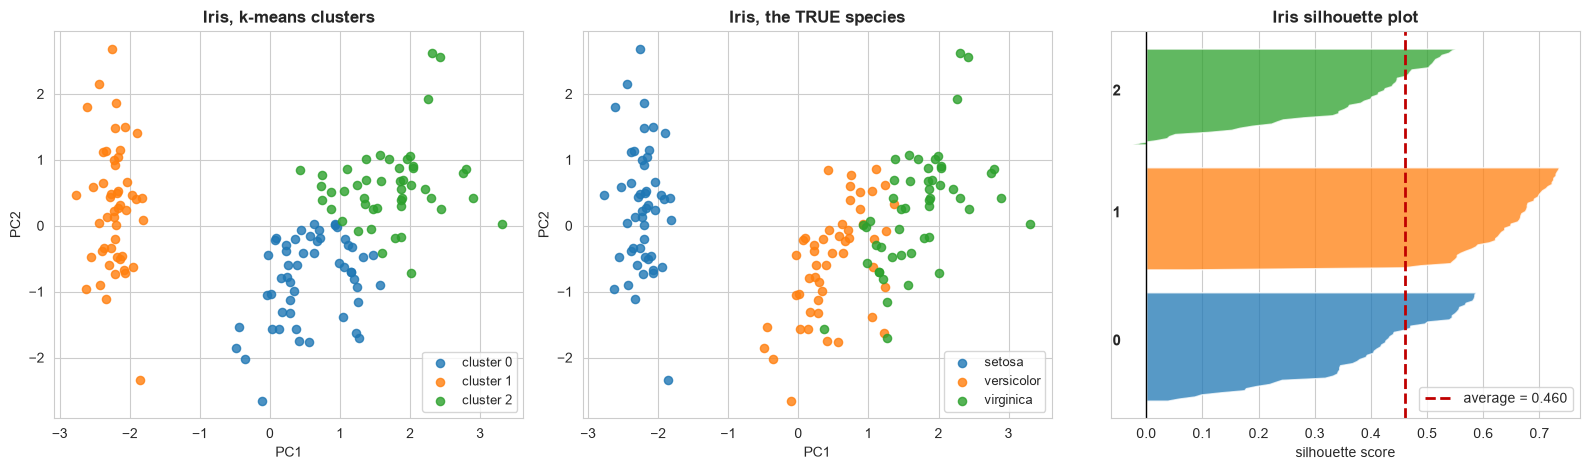

Left and middle look almost the same. The clustering nearly recovered the species.
Nobody told it there were three, or which flower was which.


In [15]:
Zi = PCA(n_components=2).fit_transform(Xi)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for c in range(3):
    m = km_i.labels_ == c
    ax[0].scatter(Zi[m, 0], Zi[m, 1], s=35, alpha=.8, label=f'cluster {c}')
ax[0].set_title('Iris, k-means clusters', fontsize=12.5, fontweight='bold')
ax[0].legend(fontsize=9)

for c in range(3):
    m = yi == c
    ax[1].scatter(Zi[m, 0], Zi[m, 1], s=35, alpha=.8, label=iris.target_names[c])
ax[1].set_title('Iris, the TRUE species', fontsize=12.5, fontweight='bold')
ax[1].legend(fontsize=9)

silhouette_plot(Xi, km_i.labels_, 'Iris silhouette plot', ax=ax[2])
for a_ in ax[:2]:
    a_.set_xlabel('PC1'); a_.set_ylabel('PC2')
plt.tight_layout(); plt.show()

print('Left and middle look almost the same. The clustering nearly recovered the species.')
print('Nobody told it there were three, or which flower was which.')

In [16]:
# Now use the labels, since this is the rare case where we have them
print('EXTERNAL VALIDATION, only possible because Iris has labels')
print()
print(f'   ARI : {adjusted_rand_score(yi, km_i.labels_):.4f}')
print(f'   NMI : {normalized_mutual_info_score(yi, km_i.labels_):.4f}')
print()
print(pd.crosstab(pd.Series(km_i.labels_, name='cluster'),
                  pd.Series([iris.target_names[t] for t in yi], name='species')).to_string())
print()
print('Two species separate almost perfectly. The third overlaps with one of them.')
print()
print('We could not do this on Ames. There are no labels, and there never were.')

EXTERNAL VALIDATION, only possible because Iris has labels

   ARI : 0.6201
   NMI : 0.6595

species  setosa  versicolor  virginica
cluster                               
0             0          39         14
1            50           0          0
2             0          11         36

Two species separate almost perfectly. The third overlaps with one of them.

We could not do this on Ames. There are no labels, and there never were.


---
# Section 7: Side by Side

In [17]:
def grade(sil):
    if sil >= 0.50: return 'clear structure'
    if sil >= 0.25: return 'overlapping'
    return 'little or none'

rows = []
for name, Xd, l in [
        ('Ames, k-means',      Xs, km.labels_),
        ('Ames, hierarchical', Xs, hc.labels_),
        ('Random noise',       noise, km_n.labels_),
        ('Iris, k-means',      Xi, km_i.labels_)]:
    s = silhouette_score(Xd, l)
    rows.append({'dataset': name,
                 'n': Xd.shape[0],
                 'clusters': len(set(l)),
                 'silhouette': round(s, 4),
                 'Davies-Bouldin': round(davies_bouldin_score(Xd, l), 4),
                 'verdict': grade(s)})
print(pd.DataFrame(rows).to_string(index=False))
print()
print('Ames sits between random noise and a dataset with real structure.')
print('Closer to noise than to Iris.')

           dataset    n  clusters  silhouette  Davies-Bouldin        verdict
     Ames, k-means 2930         4      0.2610          1.1820    overlapping
Ames, hierarchical 2930         4      0.2251          1.2140 little or none
      Random noise 2930         4      0.0807          2.4304 little or none
     Iris, k-means  150         3      0.4599          0.8336    overlapping

Ames sits between random noise and a dataset with real structure.
Closer to noise than to Iris.


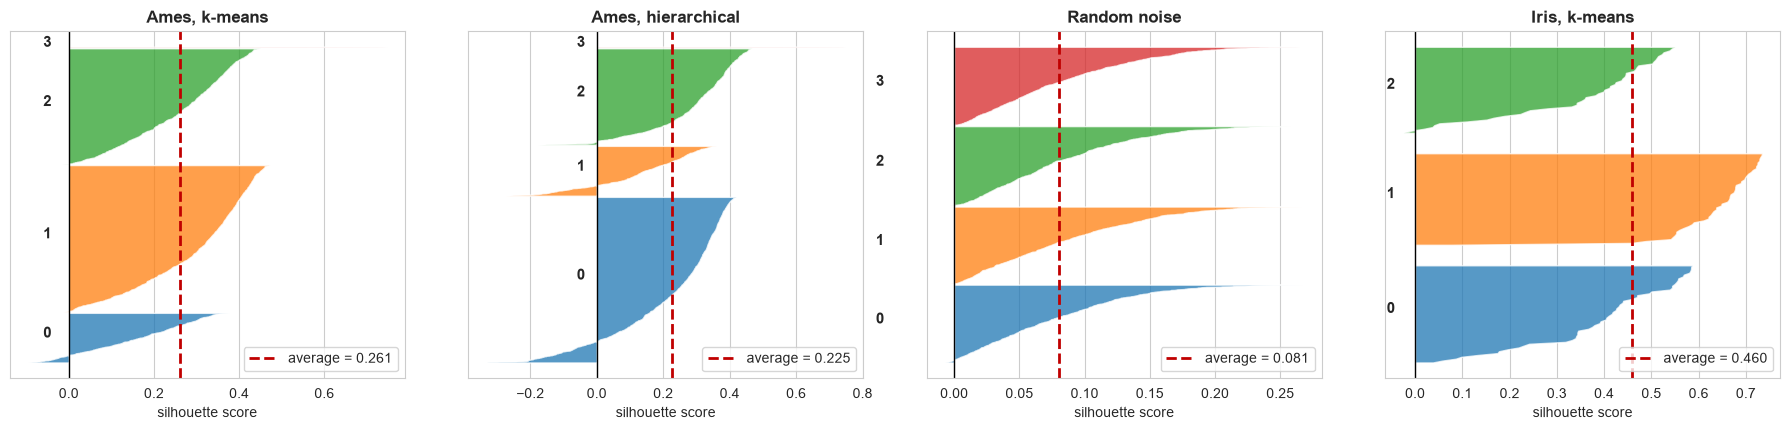

Read the shapes. Iris has long bars and few negatives.
Ames and noise look alike: short bars, many points near zero.


In [18]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.4))
for a_, (name, Xd, l) in zip(ax, [
        ('Ames, k-means', Xs, km.labels_),
        ('Ames, hierarchical', Xs, hc.labels_),
        ('Random noise', noise, km_n.labels_),
        ('Iris, k-means', Xi, km_i.labels_)]):
    silhouette_plot(Xd, l, f'{name}', ax=a_)
plt.tight_layout(); plt.show()

print('Read the shapes. Iris has long bars and few negatives.')
print('Ames and noise look alike: short bars, many points near zero.')

---
# Section 8: When the Metrics Disagree

A low silhouette does not always mean the clustering is wrong.

In [19]:
wine = load_wine()
Xw = StandardScaler().fit_transform(wine.data)
yw = wine.target
km_w = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(Xw)

print('WINE: 178 wines, 13 chemical measurements, 3 cultivars')
print()
print(f'   silhouette : {silhouette_score(Xw, km_w.labels_):.4f}   <- barely better than Ames')
print(f'   ARI        : {adjusted_rand_score(yw, km_w.labels_):.4f}   <- almost perfect')
print()
print(pd.crosstab(pd.Series(km_w.labels_, name='cluster'),
                  pd.Series([wine.target_names[t] for t in yw], name='cultivar')).to_string())
print()
print('The clustering recovered the three cultivars almost exactly.')
print('And silhouette still called it weak.')

WINE: 178 wines, 13 chemical measurements, 3 cultivars

   silhouette : 0.2849   <- barely better than Ames
   ARI        : 0.8975   <- almost perfect

cultivar  class_0  class_1  class_2
cluster                            
0               0       65        0
1               0        3       48
2              59        3        0

The clustering recovered the three cultivars almost exactly.
And silhouette still called it weak.


### Why this happens

**Silhouette measures geometry.** Are the clusters tight and far apart in space?

**ARI measures correctness.** Did we put the right things together?

Wine's three cultivars genuinely overlap in chemical space. The clusters are not
well separated, so silhouette is low. But they are the **right** clusters, so ARI
is high.

**What this means for your project**

- A low silhouette means your clusters overlap. It does **not** prove they are meaningless.
- Without labels you cannot tell the difference. Ames has no labels.
- So report the silhouette, report the stability, and **say what you cannot know**.

---
# Section 9: How to Report This Honestly

In [20]:
print('=' * 62)
print('THE FULL EVIDENCE FOR AMES')
print('=' * 62)
sil = silhouette_score(Xs, km.labels_)
sil_n = silhouette_score(noise, km_n.labels_)
aris = [adjusted_rand_score(base, KMeans(n_clusters=K, n_init=20, random_state=s)
                            .fit(Xs).labels_) for s in [1, 7, 42, 99, 123]]
print(f'   silhouette, k={K}        : {sil:.4f}   (overlapping)')
print(f'   silhouette, random noise : {sil_n:.4f}')
print(f'   ratio to noise           : {sil/sil_n:.1f}x')
print(f'   Davies-Bouldin           : {davies_bouldin_score(Xs, km.labels_):.4f}')
print(f'   ARI across seeds         : {min(aris):.2f} to {max(aris):.2f}')
print(f'   negative silhouette      : {(silhouette_samples(Xs, km.labels_) < 0).mean()*100:.1f}% of houses')
print()
print('=' * 62)
print('A HONEST REPORT, WRITTEN FROM THOSE NUMBERS')
print('=' * 62)

# built from what actually ran, not from a template
band = ('clear structure' if sil >= .50 else
        'overlapping'     if sil >= .25 else
        'little or no structure')
stable = ('highly stable' if min(aris) >= .95 else
          'mostly stable' if min(aris) >= .75 else
          'unstable')
verdict = ('a continuum rather than distinct types' if sil < .40 else
           'genuinely separated groups')

print(f'''
   We clustered {Xs.shape[0]:,} houses on {Xs.shape[1]} numeric features using
   k-means with k={K}.

   Silhouette was {sil:.2f}, which falls in the "{band}" band. The same
   algorithm on random data of the same shape scored {sil_n:.2f}, so our result
   is {sil/sil_n:.1f} times better than nothing. Davies-Bouldin was
   {davies_bouldin_score(Xs, km.labels_):.2f}.
   {(silhouette_samples(Xs, km.labels_) < 0).mean()*100:.1f}% of houses had a
   negative silhouette, meaning they sit closer to another cluster than their own.

   The structure is {stable}. Across five random seeds the agreement (ARI) ranged
   from {min(aris):.2f} to {max(aris):.2f}.

   We interpret this as {verdict}. The clusters are usable as price bands, but
   we do not claim to have discovered {K} natural kinds of house.
''')
print('   Every number above came from this notebook. Nothing was assumed.')

THE FULL EVIDENCE FOR AMES
   silhouette, k=4        : 0.2610   (overlapping)
   silhouette, random noise : 0.0807
   ratio to noise           : 3.2x
   Davies-Bouldin           : 1.1820
   ARI across seeds         : 0.76 to 1.00
   negative silhouette      : 2.8% of houses

A HONEST REPORT, WRITTEN FROM THOSE NUMBERS

   We clustered 2,930 houses on 8 numeric features using
   k-means with k=4.

   Silhouette was 0.26, which falls in the "overlapping" band. The same
   algorithm on random data of the same shape scored 0.08, so our result
   is 3.2 times better than nothing. Davies-Bouldin was
   1.18.
   2.8% of houses had a
   negative silhouette, meaning they sit closer to another cluster than their own.

   The structure is mostly stable. Across five random seeds the agreement (ARI) ranged
   from 0.76 to 1.00.

   We interpret this as a continuum rather than distinct types. The clusters are usable as price bands, but
   we do not claim to have discovered 4 natural kinds of house.


### The three questions to answer before you believe any clustering

1. **Is the silhouette clearly better than on random data of the same shape?**
2. **Does the same structure survive a different seed and a different sample?**
3. **Can you name the clusters in words somebody in the domain would use?**

---
